# Fundamentals of Machine Learning - Exercise 3
* Goal of the excercise is to learn about more advanced vizualization techniques.


![meme1](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_03_meme_02.jpg?raw=true)


## We will use House prices dataset once more

Data source: https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data

Important attributes description:
* SalePrice: The property's sale price in dollars. This is the target variable that you're trying to predict.
* MSSubClass: The building class
* BldgType: Type of dwelling
* HouseStyle: Style of dwelling
* OverallQual: Overall material and finish quality
* OverallCond: Overall condition rating
* YearBuilt: Original construction date
* Heating: Type of heating
* CentralAir: Central air conditioning
* GrLivArea: Above grade (ground) living area square feet
* BedroomAbvGr: Number of bedrooms above basement level

## Import packages

In [1]:
import pandas as pd # dataframes
import numpy as np # matrices and linear algebra
import matplotlib.pyplot as plt # plotting
import seaborn as sns # another matplotlib interface - styled and easier to use

## Load the data into the Pandas DataFrame
* https://raw.githubusercontent.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/master/datasets/zsu_cv1_data.csv

In [2]:
import pandas as pd

# URL datasetu
url = "https://raw.githubusercontent.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/master/datasets/zsu_cv1_data.csv"

# Načítanie CSV súboru
df = pd.read_csv(url)

# Prvých 5 riadkov
df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 🔎 What does the *...* in the middle of table columns mean?

### 💡 Hint: If the dataset has too many columns, it is good to set pandas parameter **display.max_columns** to None so there is no such limit

In [3]:
with pd.option_context('display.max_columns', None):
    display(df)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA,TA,CBlock,Gd,TA,No,ALQ,790,Rec,163,589,1542,GasA,TA,Y,SBrkr,2073,0,0,2073,1,0,2,0,3,1,TA,7,Min1,2,TA,Attchd,1978.0,Unf,2,500,TA,TA,Y,349,0,0,0,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,

# Let's start with the plots already!

# 📊 Pairplot
* Plot pairwise relationships in a dataset
    * i.e. **Scatterplots for multiple pairs of numerical attributes**
    * See [this](https://seaborn.pydata.org/generated/seaborn.pairplot.html) for more details

## Select only interesting features for pairplot visualization
* 💡 The pairplot might be too big to see anything in the visualization otherwise
* Select just subset of features and use *vars* parameter for it

> ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'SalePrice']

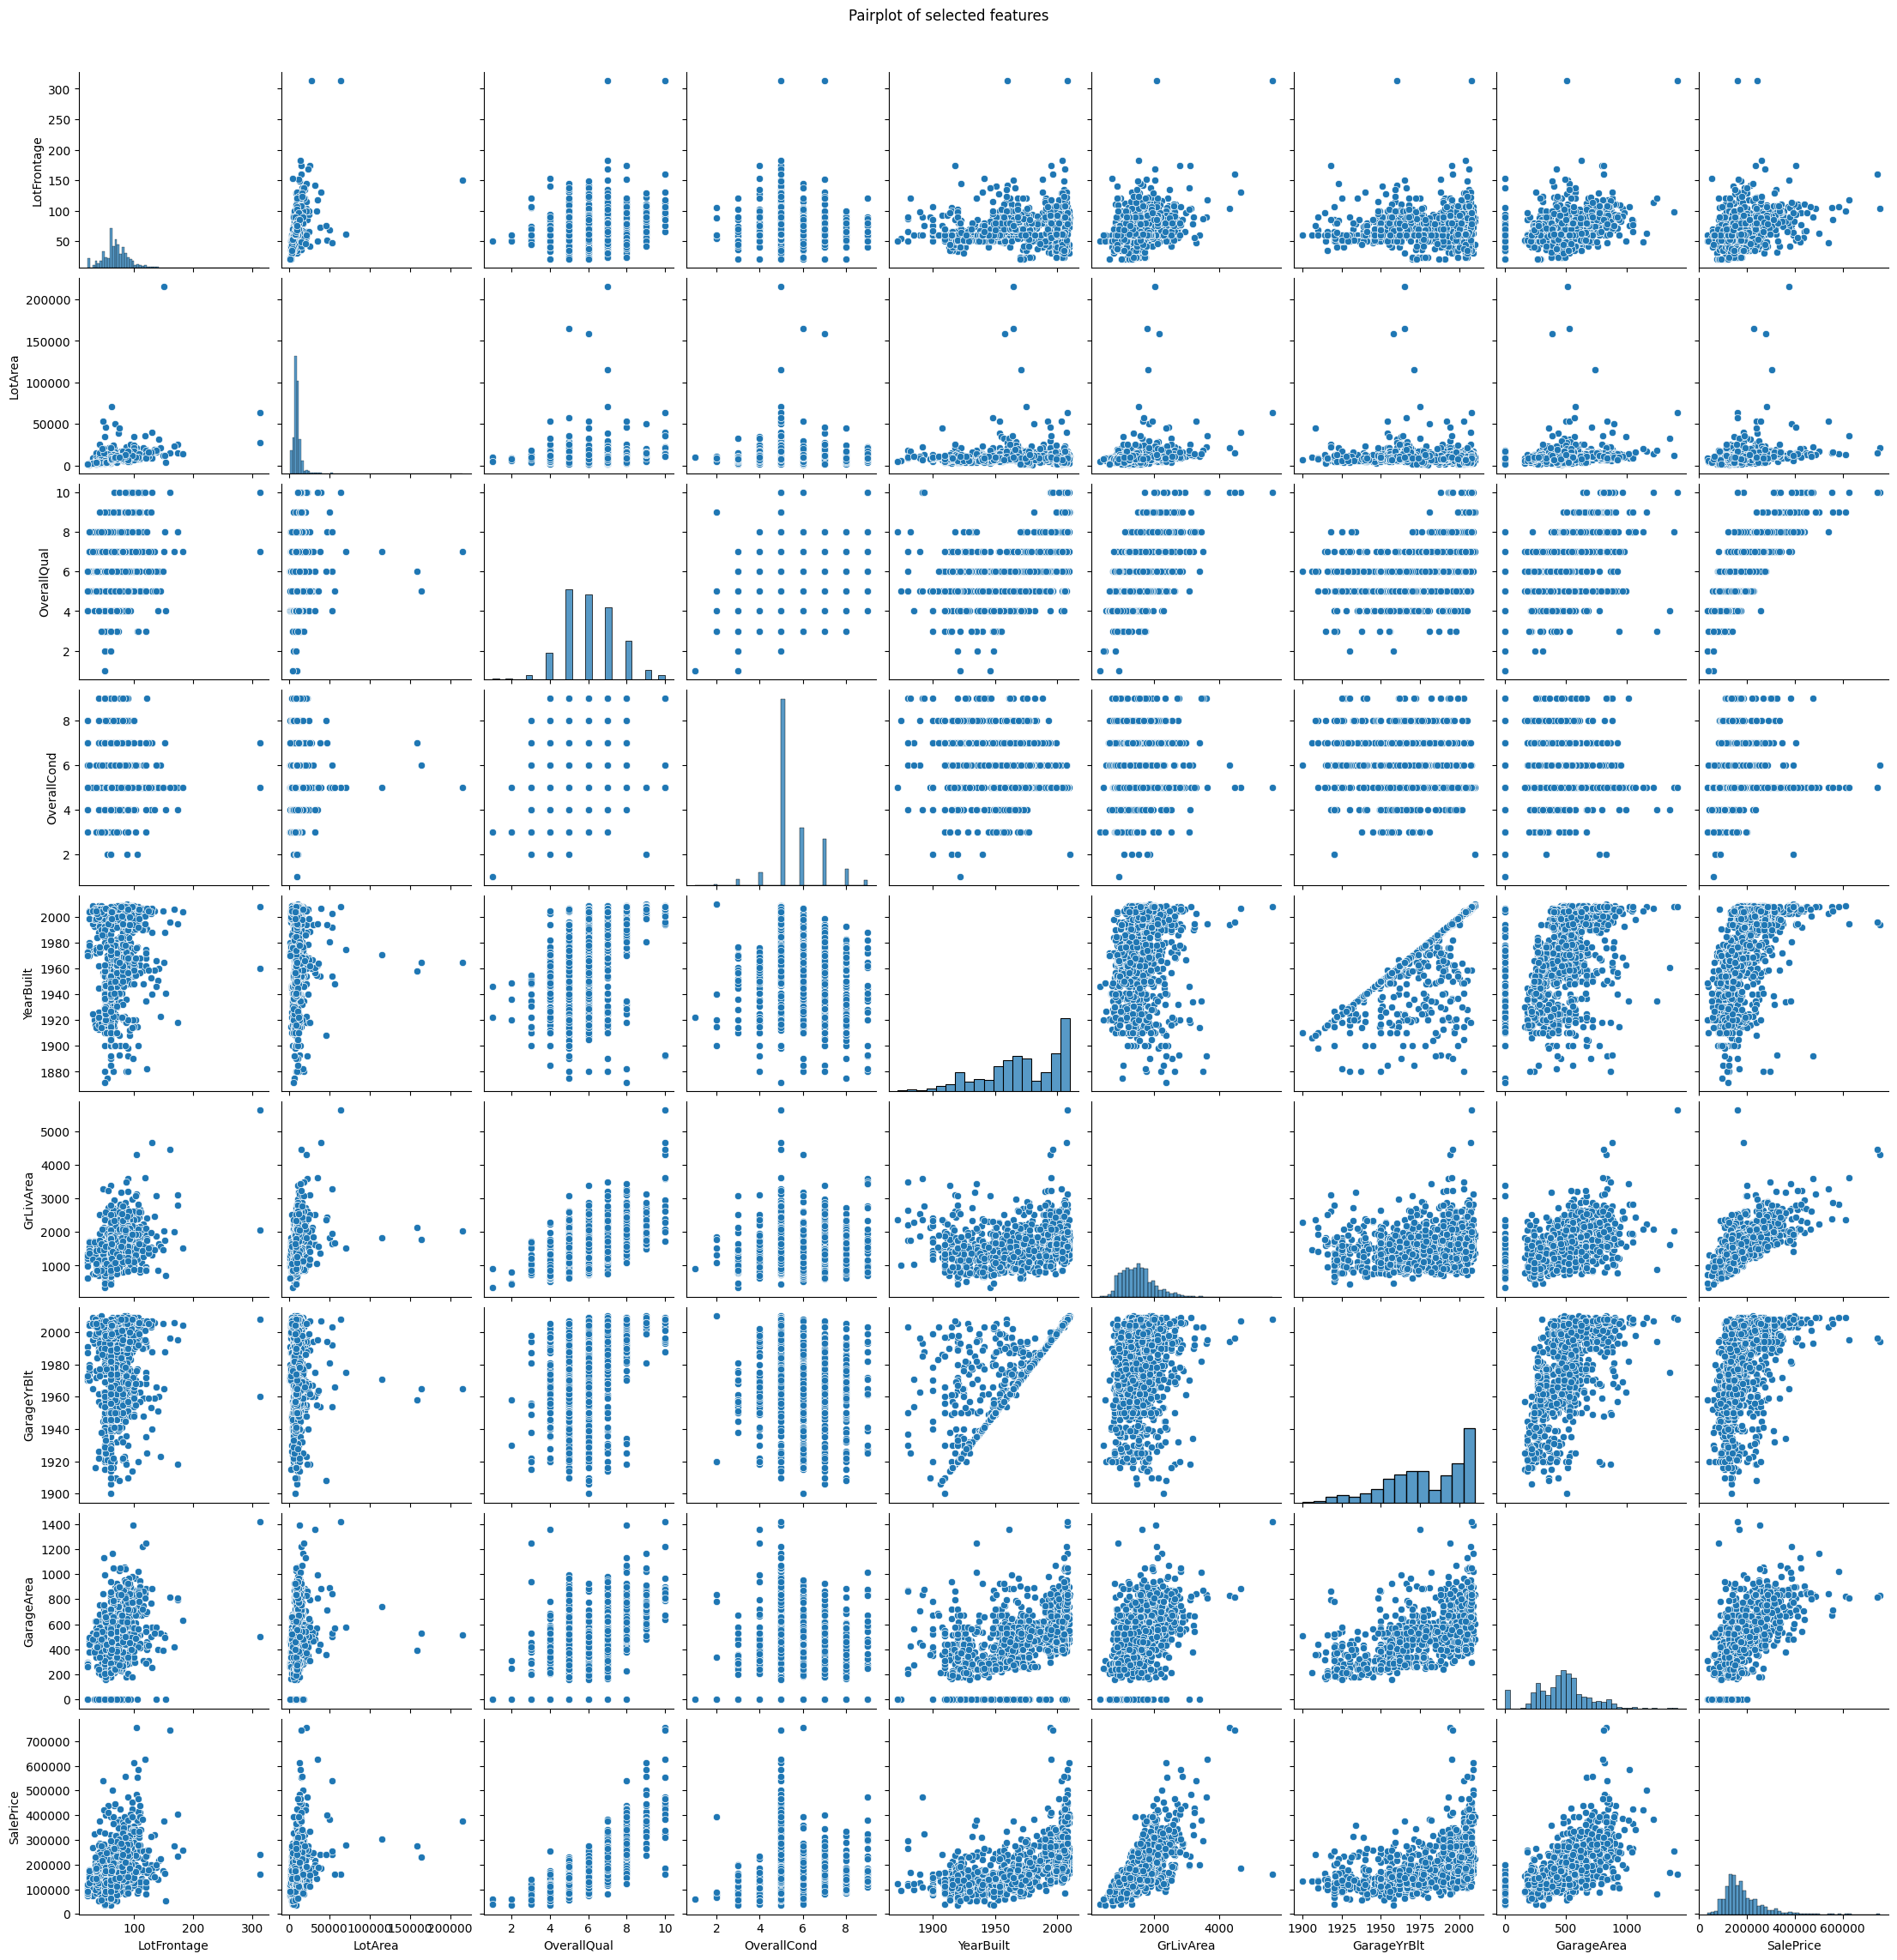

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Definujme zaujímavé numerické stĺpce
selected_features = [
    'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
    'YearBuilt', 'GrLivArea', 'GarageYrBlt', 'GarageArea',
    'SalePrice'
]

# Vytvor pairplot
sns.pairplot(df[selected_features])
plt.suptitle("Pairplot of selected features", y=1.02)
plt.show()


## 💡 Notice that both OverallQual and OverallCond columns are rather categorical features
* Even though they are represented by numerical values
    * So one would expect that the features are numerical, but they aren't

* Scatter plot may not be the best way to visualize this type of data
    * 🔎 What type of plot is more reseonable?

* Let's select only appropropriate features this time
* Also distinguish among different **BldgType** in the plot
    * *hue* parameter 

> ['LotFrontage', 'LotArea', 'YearBuilt', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'SalePrice']

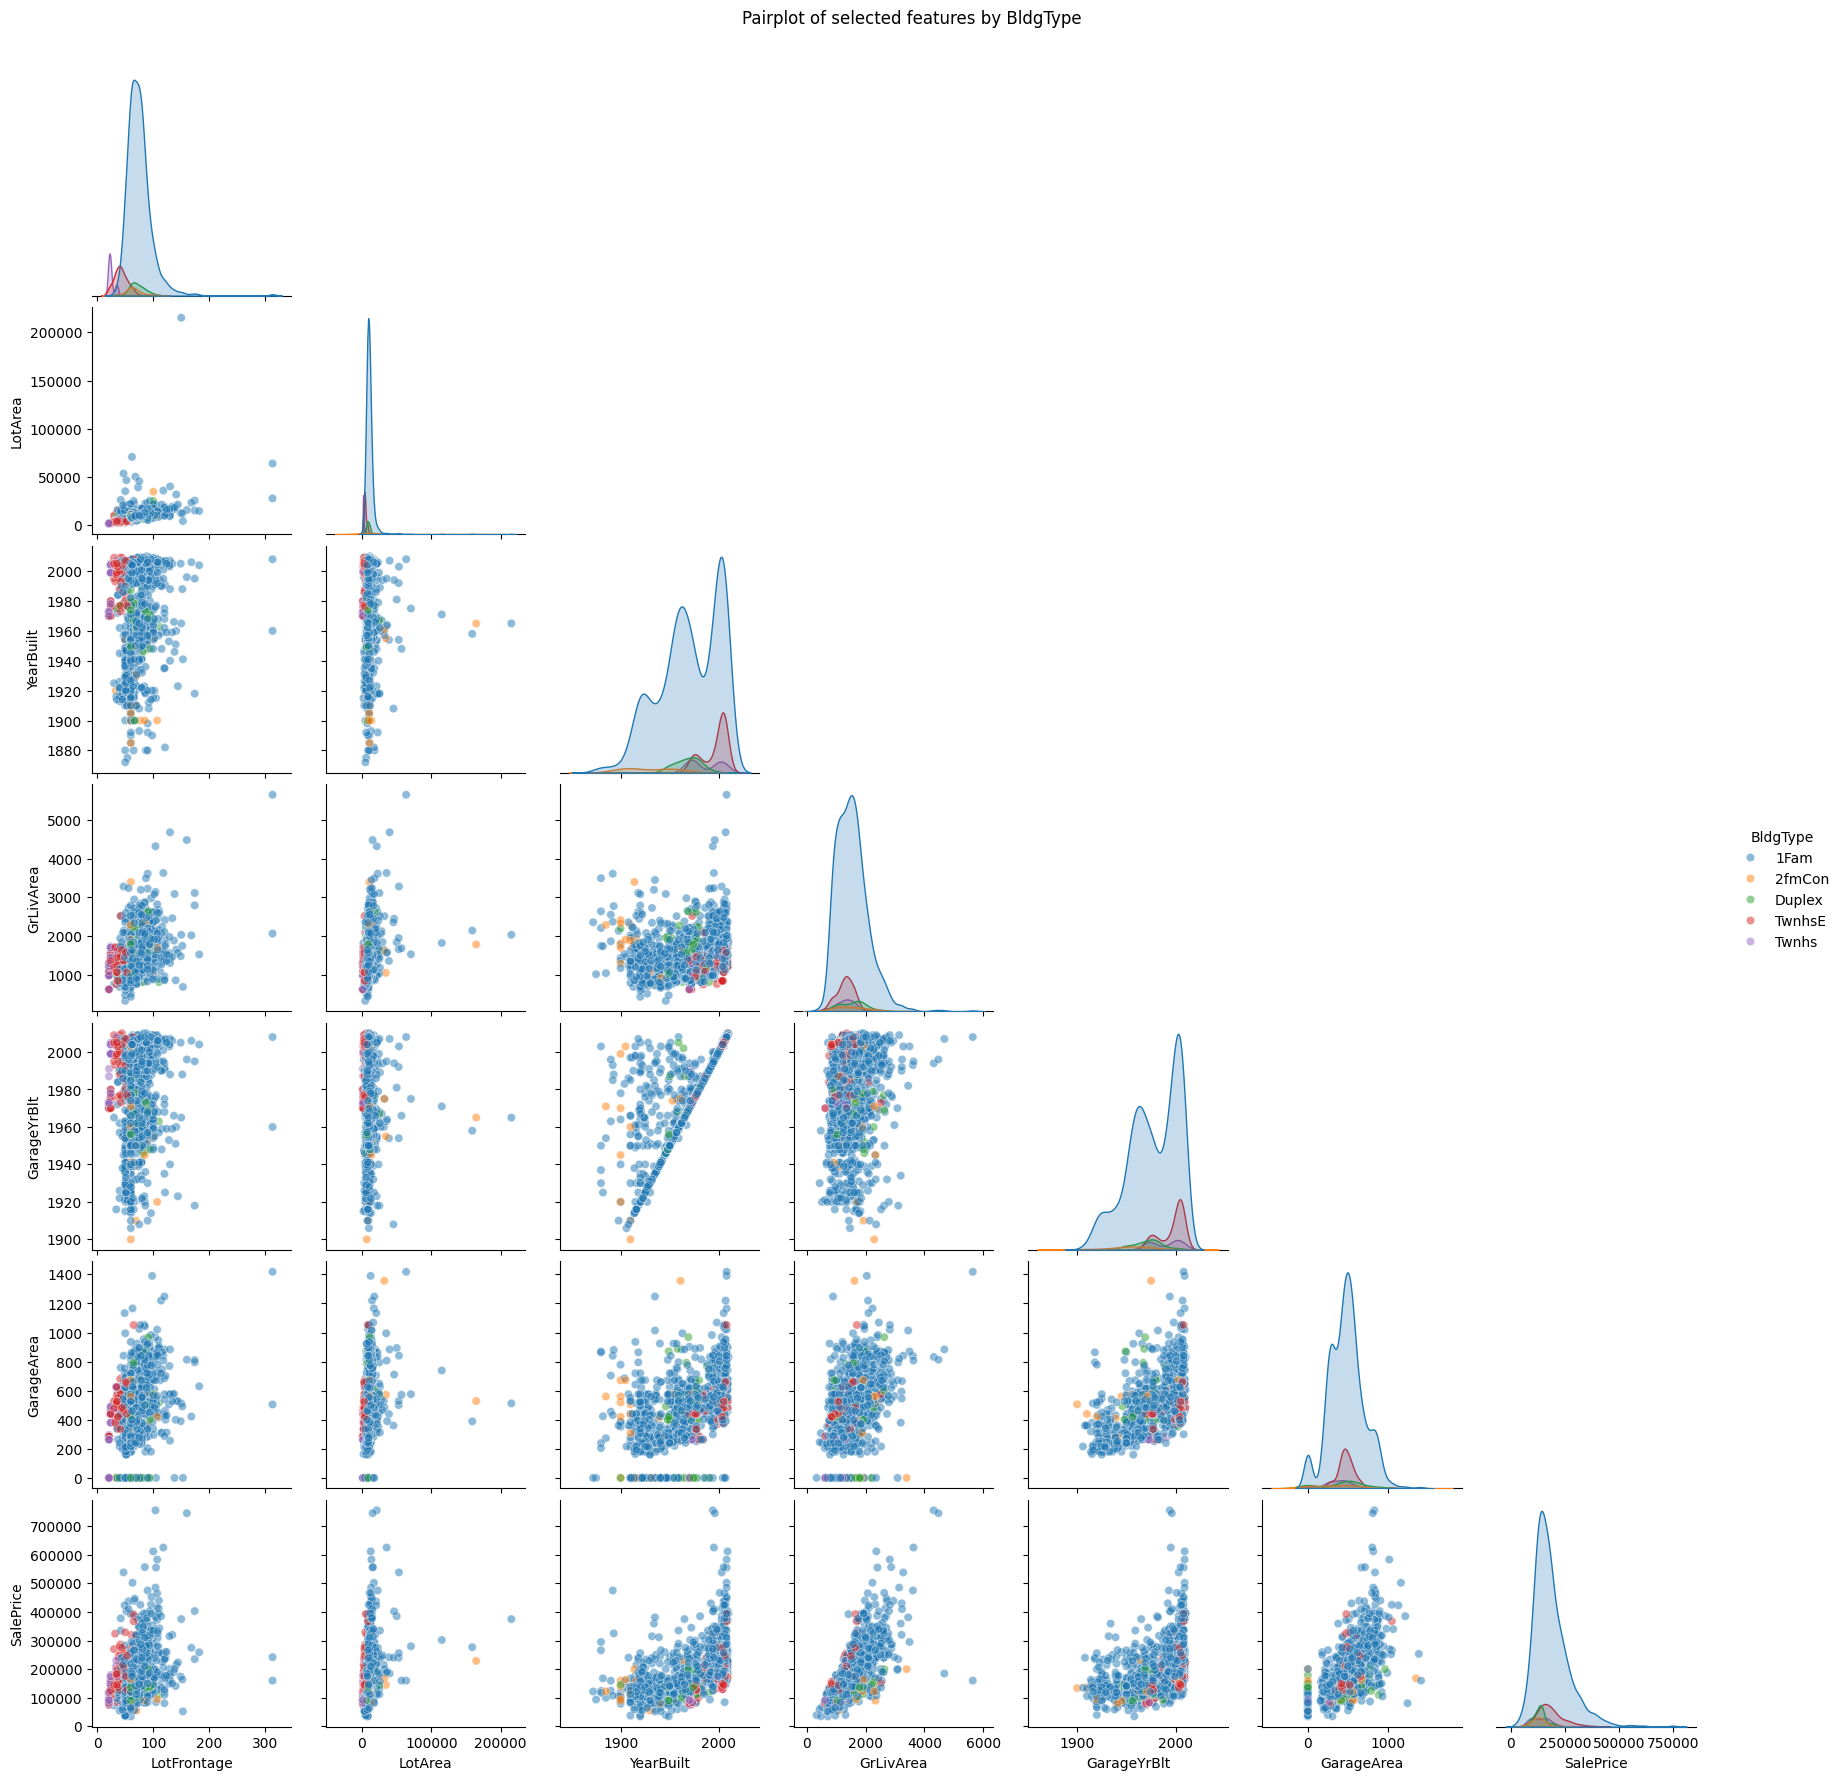

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Vybrané číselné atribúty
selected_features = [
    'LotFrontage', 'LotArea', 'YearBuilt',
    'GrLivArea', 'GarageYrBlt', 'GarageArea', 'SalePrice'
]

# Pairplot s rozlíšením podľa typu budovy (kategória)
sns.pairplot(
    df,
    vars=selected_features,
    hue="BldgType",
    corner=True,
    plot_kws={"alpha": 0.5}
)
plt.suptitle("Pairplot of selected features by BldgType", y=1.02)
plt.show()


## In the following steps we want to threat OverallQual and OverallCond as categories instead of numbers
* for modifying of column's types you can use function *astype*

In [6]:
# Premena číselných hodnôt na kategórie
df["OverallQual"] = df["OverallQual"].astype("category")
df["OverallCond"] = df["OverallCond"].astype("category")

# Overíme typy
df[["OverallQual", "OverallCond"]].dtypes


OverallQual    category
OverallCond    category
dtype: object

# 🔎 Are you able to say which categorical attributes affect the price right now?
- Yeah... me neither so let's find out by plotting the data first 🙂

## Start with a selection of only the categorical features
* Use *select_dtypes* function with *exclude* parameter to get rid of numerical (*np.number*) attributes
    * Save these column names into a variable
* Loop over the selected columns and fill *NaN* values with **'MISSING'** string

In [8]:
# Získame nekonvertované kategórie (nekonvertované stĺpce – object alebo category)
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

for col in categorical_cols:
    # Ak je stĺpec typu category, pridaj novú kategóriu 'MISSING'
    if df[col].dtype.name == "category":
        df[col] = df[col].cat.add_categories("MISSING")
    
    # Nahradíme NaN reťazcom 'MISSING'
    df[col] = df[col].fillna("MISSING")


## Check the result

In [9]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,MISSING,Reg,Lvl,AllPub,...,0,MISSING,MISSING,MISSING,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,MISSING,Reg,Lvl,AllPub,...,0,MISSING,MISSING,MISSING,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,MISSING,IR1,Lvl,AllPub,...,0,MISSING,MISSING,MISSING,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,MISSING,IR1,Lvl,AllPub,...,0,MISSING,MISSING,MISSING,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,MISSING,IR1,Lvl,AllPub,...,0,MISSING,MISSING,MISSING,0,12,2008,WD,Normal,250000


![meme2](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_03_meme_01.jpg?raw=true)

# 📊 Very useful feature is the [subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) function 
* It is useful for defining our own grids for plots based on our needs

## We will plot boxplots of *SalePrice* along with the value counts using barplot for each categorical feature
* **🔎 Why is this pair of plots useful?**

* The *subplots* function has 3 important parameters
    1. Number of rows - *nrows*
    2. Number of columns - *ncols*
    3. Figure size - *figsize*
* It returns a *figure* and *axes* objects
    * The *axes* contains reference to individual subplots
    * 💡 Use *flat* property to access 1D array of subplots

In [13]:
for i, col in enumerate(qualitative_columns):
    ax_left = axes[i, 0]
    ax_right = axes[i, 1]

    sns.boxplot(data=df, x=col, y="SalePrice", ax=ax_left)
    ax_left.set_title(f"SalePrice by {col}")
    ax_left.tick_params(axis='x', rotation=45)

    sns.countplot(data=df, x=col, ax=ax_right, order=df[col].value_counts().index)
    ax_right.set_title(f"Count of {col}")
    ax_right.tick_params(axis='x', rotation=45)


# 📊 Correlation
* 🔎 What does the *correlation coefficient* tell you?
* What is the range of it?
* Is it useful for each type of relationship?
* 💡 **Correlation is not causation**
    * e.g. Ice cream sales X Number of thefts

- Take a look at [this link](https://www.dummies.com/education/math/statistics/how-to-interpret-a-correlation-coefficient-r/)
- See also [this](https://www.simplypsychology.org/correlation.html) or [this](https://www.investopedia.com/ask/answers/032515/what-does-it-mean-if-correlation-coefficient-positive-negative-or-zero.asp) for some more info about the topic

## We can compute the correlation matrix using *corr()* function
* Select columns first

> ['LotFrontage', 'LotArea', 'YearBuilt', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'SalePrice']

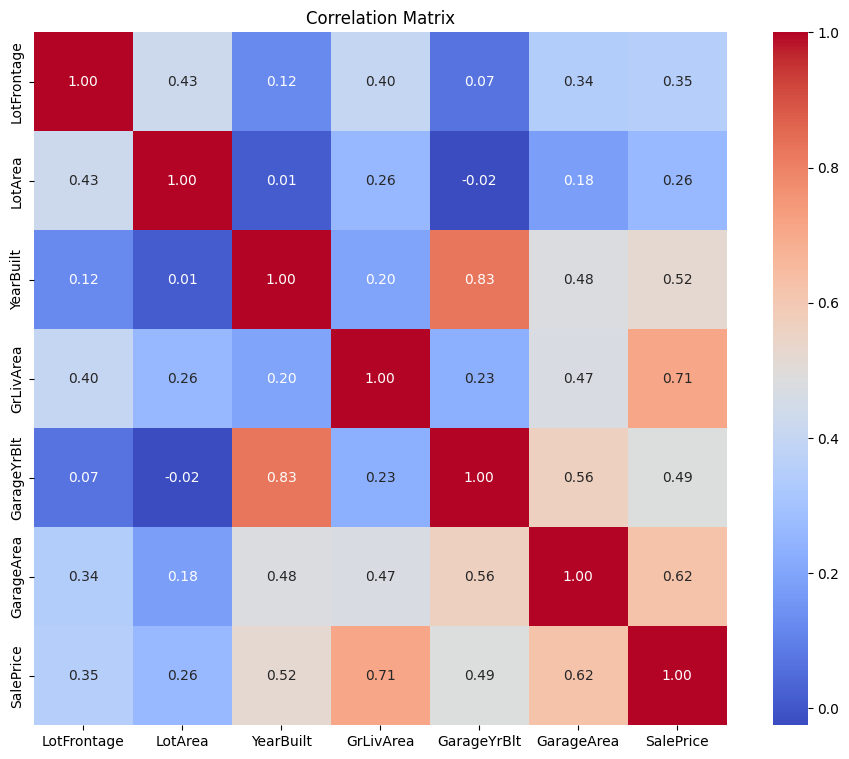

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# 🧮 Vyber relevantné číselné stĺpce
cols = ['LotFrontage', 'LotArea', 'YearBuilt', 'GrLivArea', 
        'GarageYrBlt', 'GarageArea', 'SalePrice']

# 📈 Korelačná matica
corr_matrix = df[cols].corr()

# 🔥 Vykreslenie heatmapy
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Correlation Matrix")
plt.show()


## 📊 Vizualize the matrix using *heatmap* plot

In [15]:
plt.figure(figsize=(12, 9))


<Figure size 1200x900 with 0 Axes>

<Figure size 1200x900 with 0 Axes>

## Which color scheme will be more appropropriate for corellation representation?
- Change color map *cmap* (e.g. RdYlGn)
- Set limits to adjust color map values from -1 to 1
    - Attributes *vmin*, *vmax*

In [16]:
plt.figure(figsize=(12, 9))


<Figure size 1200x900 with 0 Axes>

<Figure size 1200x900 with 0 Axes>

## Add values to the heatmap and amplify heatmap's readability
* Use *cmap=sns.light_palette("seagreen", as_cmap=True)* color map
* Set minimum value to **0.3**
* Enable annotations using *annot* parameter
* Plot each column as a *square* (same name of the parameter)

In [17]:
plt.figure(figsize=(12, 9))


<Figure size 1200x900 with 0 Axes>

<Figure size 1200x900 with 0 Axes>

# 💡 I highly recommend taking a look at the plot gallery for some more plots!
* https://seaborn.pydata.org/api.html

## 📊 Let's try for example scatter plot with regression line fron the example gallery
* 🔎 What insight does it give us about the trend?

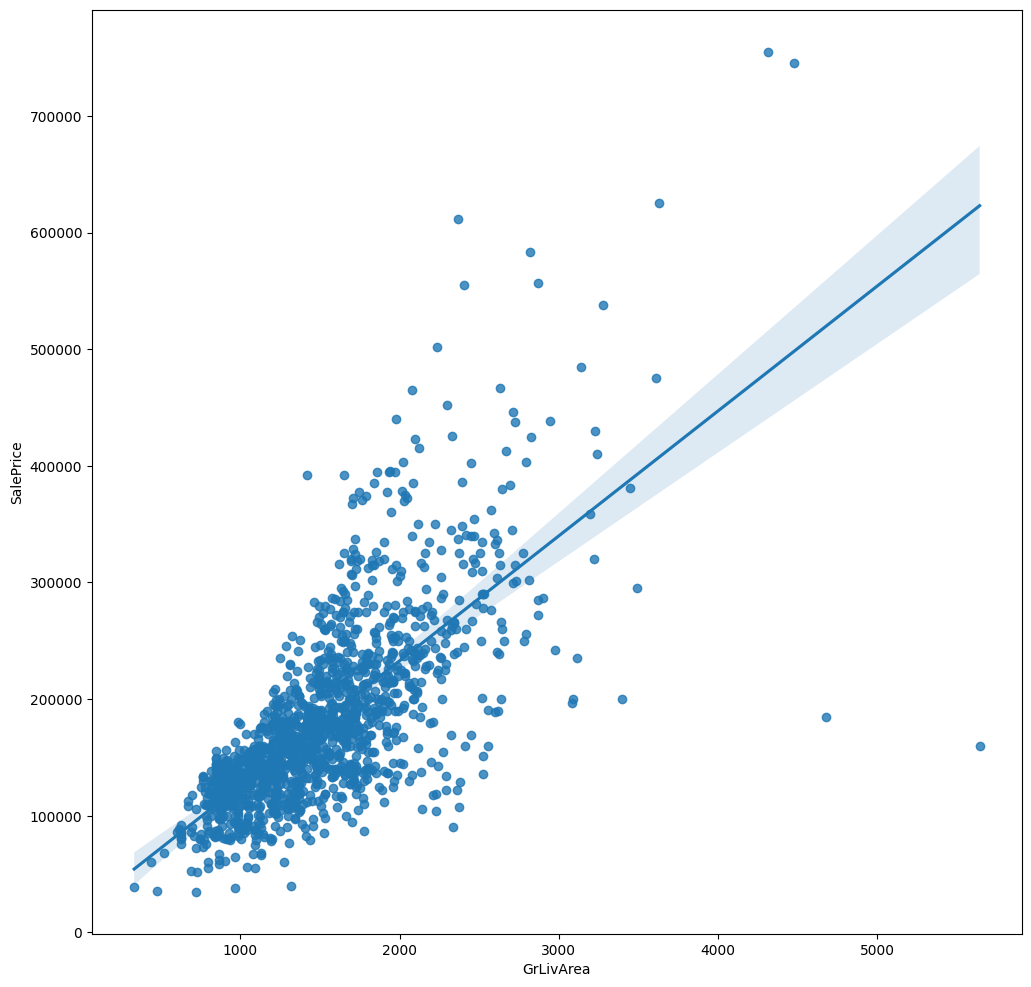

In [18]:
fig = plt.figure(figsize=(12, 12))
sns.regplot(data = df, x='GrLivArea', y='SalePrice')
plt.show()

# ✅ Task (2p)
1. Create two filtered dataframes:
    * The first one *df_fam* will contain only the data for **BldgType** = '1Fam'
    * The second one *df_twn* will contain only the data for **BldgType** = 'Twnhs' or 'TwnhsE'

2. Plot two correlation matrices
    * 💡 One for each of the datasets and use these features:
    > ['LotFrontage', 'LotArea', 'YearBuilt', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'SalePrice']

3. Do you see any differences or similarities in the correlation matrices?
    * Which features you take as correlated and which are not according to you?
    * **Describe the insight you got from the plots with a few sentences in a Markdown cell below the plot**
        * ❌ Plot interpretation figured in real-time during task check is not allowed! ❌

In [ ]:
✅ Task (2p)

Create two filtered dataframes:

The first one df_fam will contain only the data for BldgType = '1Fam'

The second one df_twn will contain only the data for BldgType = 'Twnhs' or 'TwnhsE'

In [23]:
# Filter pre rodinné domy (1Fam)
df_fam = df[df['BldgType'] == '1Fam']

# Filter pre radové domy (Townhouses)
df_twn = df[df['BldgType'].isin(['Twnhs', 'TwnhsE'])]


In [ ]:
2. Plot two correlation matrices
    * 💡 One for each of the datasets and use these features:
    > ['LotFrontage', 'LotArea', 'YearBuilt', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'SalePrice']

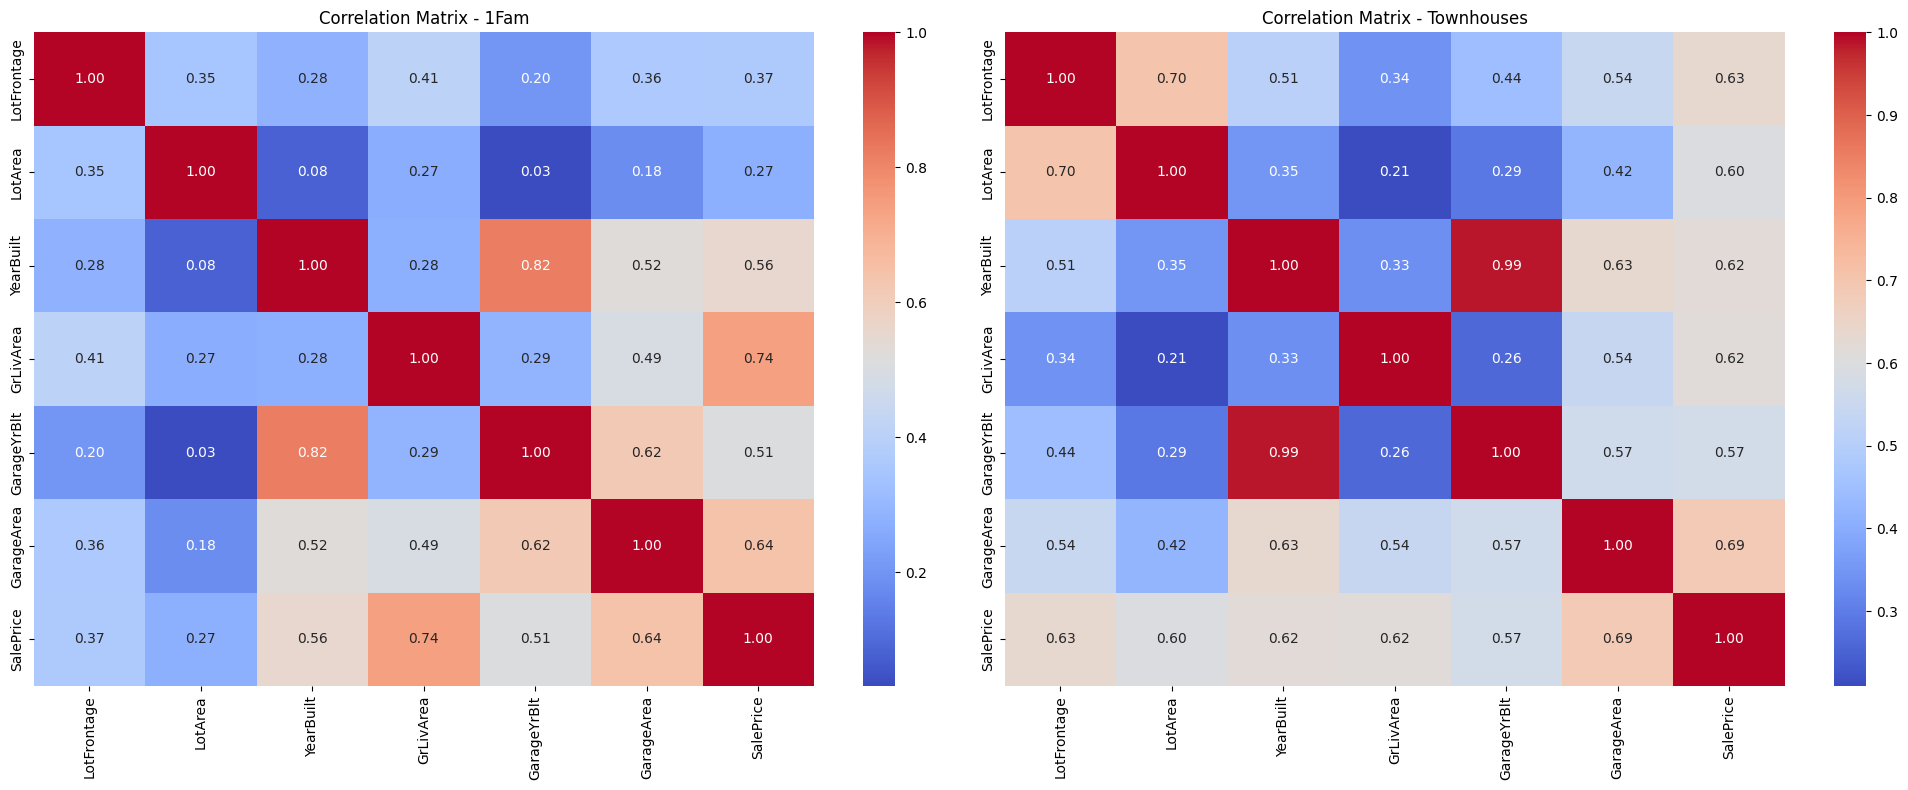

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ['LotFrontage', 'LotArea', 'YearBuilt', 'GrLivArea', 
        'GarageYrBlt', 'GarageArea', 'SalePrice']

# – rodinné domy
corr_fam = df_fam[cols].corr()

# – townhouses
corr_twn = df_twn[cols].corr()

# Vizualizácia oboch
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Rodinné domy
sns.heatmap(corr_fam, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0])
axes[0].set_title('Correlation Matrix - 1Fam')

# Townhouses
sns.heatmap(corr_twn, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1])
axes[1].set_title('Correlation Matrix - Townhouses')

plt.tight_layout()
plt.show()


In [ ]:
 Do you see any differences or similarities in the correlation matrices?
    * Which features you take as correlated and which are not according to you?
    * **Describe the insight you got from the plots with a few sentences in a Markdown cell below the plot**
        * ❌ Plot interpretation figured in real-time during task check is not allowed! ❌

In [ ]:
Postreh z korelačných matíc

GrLivArea (obytná plocha) vykazuje silnú pozitívnu koreláciu s SalePrice (predajná cena) pri oboch typoch domov, avšak táto korelácia je silnejšia pri rodinných domoch (1Fam).

GarageArea (plocha garáže) a GarageYrBlt (rok výstavby garáže) tiež stredne silne korelujú s cenou pri rodinných domoch, no tento vzťah je slabší pri radových domoch (townhouses).

LotArea (plocha pozemku) má slabú alebo žiadnu koreláciu pri radových domoch, ale miernu koreláciu pri rodinných domoch.

Pri radových domoch sa všeobecne vyskytuje menej silných korelácií s cenou — čo dáva zmysel, keďže tieto domy sú zvyčajne viac štandardizované a menej variabilné ako samostatne stojace domy.

Záver: Samostatne stojace domy (1Fam) majú väčšiu variabilitu vo vlastnostiach, ktoré ovplyvňujú cenu, zatiaľ čo radové domy (Twnhs, TwnhsE) sú viac jednotné, čo vedie k slabším alebo menej početným koreláciám.